Comparative Evaluation of Classical Machine Learning Algorithms for Breast Cancer Classification

1. Introduction
Machine learning is increasingly being applied to classification problems across different fields, including healthcare. Classification algorithms can analyse patterns in datasets and use those patterns to predict the categories of new observations.

This project investigates the performance of three classical machine learning algorithms: Logistic Regression, K-Nearest Neighbours (KNN), and Random Forest.
The models will be evaluated using the Breast Cancer Wisconsin Diagnostic dataset, which contains numerical measurements derived from digitised images of breast mass samples.
The experiment compares the models using accuracy, precision, recall, F1-score and confusion matrices. Particular attention is given to the detection of malignant cases because incorrectly classifying a malignant sample as benign is an important prediction error.

The goal is to establish a reproducible baseline comparison, 
understand the strengths and limitations of the selected algorithms, 
and develop practical experience in machine learning experimentation.



2. Research Question and Objectives

Research Question
How do Logistic Regression, K-Nearest Neighbours and Random Forest compare in their ability to classify malignant and benign cases using the Breast Cancer Wisconsin Diagnostic dataset?

Research Objectives
The objectives of this project are to:
1.Load and explore the Breast Cancer Wisconsin Diagnostic dataset.
2.Prepare the dataset for supervised machine learning.
3.Implement Logistic Regression, K-Nearest Neighbours and Random Forest classifiers.
4.Evaluate the models using accuracy, precision, recall and F1-score.
5.Compare the models using confusion matrices.
6.Identify the strengths and limitations of each model based on the experimental results.
7.Document the methodology and findings in a reproducible format.


In [10]:
import pandas as pd
from sklearn.datasets import load_breast_cancer


In [27]:
data=load_breast_cancer()

print('Dataset: Breast Cancer Wisconsin Diagnotics')

print('Number of observation:',data.data.shape[0])

print('Number of features:',data.data.shape[1])

print('\n Features name:')
print(data.feature_names)

print('\nTarget name:')
print(data.target_names)

print('\nTarget distribution:')
print(pd.Series(data.target).value_counts())

Dataset: Breast Cancer Wisconsin Diagnotics
Number of observation: 569
Number of features: 30

 Features name:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

Target name:
['malignant' 'benign']

Target distribution:
1    357
0    212
Name: count, dtype: int64


3. Dataset Description

This project uses the Breast Cancer Wisconsin Diagnostic dataset provided through the scikit-learn dataset collection.

The dataset contains 569 observations and 30 numerical features. These features represent measurements derived from digitised images of breast mass samples.

The classification task involves two categories:
Malignant (0)
Benign (1)

The dataset provides labelled observations, making it suitable for supervised binary classification.

The input features are used to train the machine learning models, while the target variable provides the corresponding class labels.

The dataset is used for educational and experimental purposes in this project.


4. Tools and Technologies
The following tools and Python libraries are used:
Tool or Library                    Purpose
Python                             Programming language
Pandas                             Data handling and exploration
NumPy                              Numerical computing
Scikit-learn                       Machine learning implementation
StandardScaler                     Feature standardisation
Matplotlib                         Data visualisation
Jupyter Notebook                   Experiment development and documentation

The machine learning algorithms used are Logistic Regression, K-Nearest Neighbours and Random Forest.


In [28]:
X=pd.DataFrame(
    data.data,
    columns=data.feature_names
)
y=pd.Series(data.target)

In [ ]:
print(X.head()) #inspecting the top five rows of the dataset

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [ ]:
print(X.info()) #inspecting the Dataset structure

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [ ]:
print(X.isnull().sum()) #checking for possible missing values

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64


In [35]:
#Printing the total missing values in the dataset
print('Total Missing Values: ',X.isnull().sum().sum())

Total Missing Values:  0


In [36]:
print(X.describe())

       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.000000   
25%      

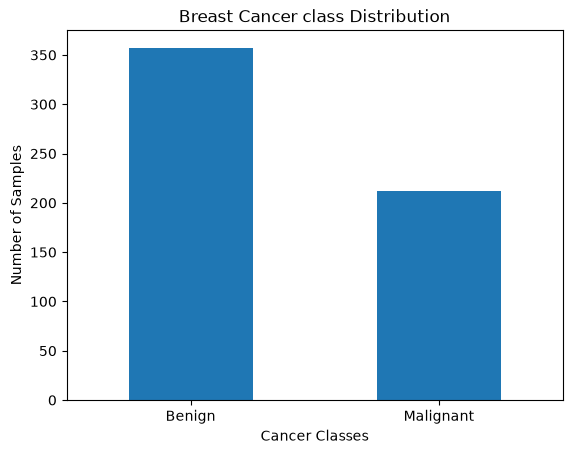

In [51]:
import matplotlib.pyplot as plt

class_counts = y.value_counts()
class_counts.index=['Benign','Malignant']

class_counts.plot(kind='bar')

plt.title("Breast Cancer class Distribution")
plt.xlabel("Cancer Classes")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)

plt.show()

Data Preparation

Data preparation involves organising the dataset into input features and target labels before training the machine learning models.
The input features (X) contain the 30 numerical measurements used by the models to make predictions, while the target variable (y) contains the corresponding class labels.

The target classes are encoded as follows:
0: Malignant
1: Benign
Separating the features and target allows the models to learn the relationship between the input measurements and their corresponding classification labels.


Train-Test Splitting

The dataset is divided into training and testing sets using an 80/20 split.
The training set is used to fit the machine learning models, while the test set is reserved for evaluating their performance on observations that were not used during training.
Stratified sampling is applied to preserve the approximate distribution of the target classes across both sets. A fixed random state is also used to make the data split reproducible.


In [54]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (455, 30)
Testing features: (114, 30)
Training labels: (455,)
Testing labels: (114,)


In [ ]:
print("Original class distribution:")
print(y.value_counts(normalize=True))


print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))


print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))


Original class distribution:
1    0.627417
0    0.372583
Name: proportion, dtype: float64

Training class distribution:
1    0.626374
0    0.373626
Name: proportion, dtype: float64

Testing class distribution:
1    72
0    42
Name: count, dtype: int64


Preprocessing and Leakage Prevention

Feature standardisation is applied to Logistic Regression and K-Nearest Neighbours using scikit-learn Pipelines.
StandardScaler transforms numerical features based on statistics learned from the training data. These same learned parameters are then applied to the test data.
Using a Pipeline ensures that preprocessing is fitted as part of the model training process, helping prevent information from the test set from influencing the training process.
Random Forest is used without feature standardisation because its decision-tree-based splitting process does not generally depend on feature magnitude in the same way as distance-based algorithms.

Model Development

Three supervised machine learning algorithms were selected for this classification experiment.
1 Logistic Regression
Logistic Regression is a supervised classification algorithm that estimates the probability of an observation belonging to a particular class.
It was selected as a baseline model because it provides a relatively simple approach to binary classification.

2 K-Nearest Neighbours (KNN)
K-Nearest Neighbours is a distance-based classification algorithm. It predicts the class of a new observation by examining the classes of its nearest training observations.
Feature standardisation is applied because differences in feature scales can influence distance calculations.

3 Random Forest
Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.
It was selected to investigate whether combining multiple trees produces better classification performance than the other selected algorithms.

4 Model Comparison
The three algorithms provide different approaches to classification. Comparing them allows us to examine their performance under the same training and testing conditions.


In [57]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier


logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])


knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])


random_forest = RandomForestClassifier(
    random_state=42,
    n_estimators=100
)


models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Random Forest": random_forest
}


In [58]:
for name, model in models.items():
    print(name)
    print(model)
    print("-" * 40)


Logistic Regression
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=5000))])
----------------------------------------
KNN
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier())])
----------------------------------------
Random Forest
RandomForestClassifier(random_state=42)
----------------------------------------


Visualisation and Error Analysis

Visualisation is used to communicate and compare the performance of the three classification models.
The evaluation focuses on overall accuracy, malignant-class precision and malignant-class recall. Confusion matrices are also examined to identify incorrect predictions.
Particular attention is given to false negatives for the malignant class because these represent malignant samples incorrectly classified as benign.


In [60]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


import pandas as pd
import matplotlib.pyplot as plt


results = {}
all_predictions = {}


for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)


    all_predictions[name] = predictions


    results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Malignant Precision": precision_score(
            y_test, predictions, pos_label=0
        ),
        "Malignant Recall": recall_score(
            y_test, predictions, pos_label=0
        ),
        "Malignant F1-score": f1_score(
            y_test, predictions, pos_label=0
        )
    }


results_df = pd.DataFrame(results).T


print(results_df.round(4))


                     Accuracy  Malignant Precision  Malignant Recall  \
Logistic Regression    0.9825               0.9762            0.9762   
KNN                    0.9561               0.9512            0.9286   
Random Forest          0.9561               0.9512            0.9286   

                     Malignant F1-score  
Logistic Regression              0.9762  
KNN                              0.9398  
Random Forest                    0.9398  


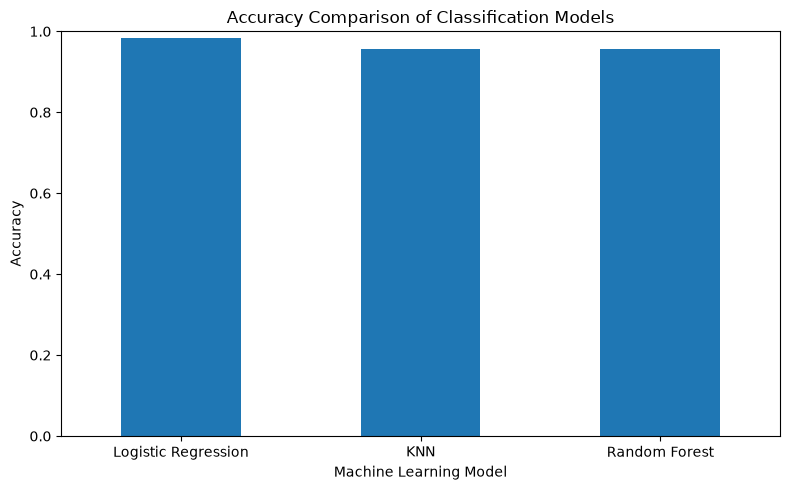

In [61]:
results_df["Accuracy"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


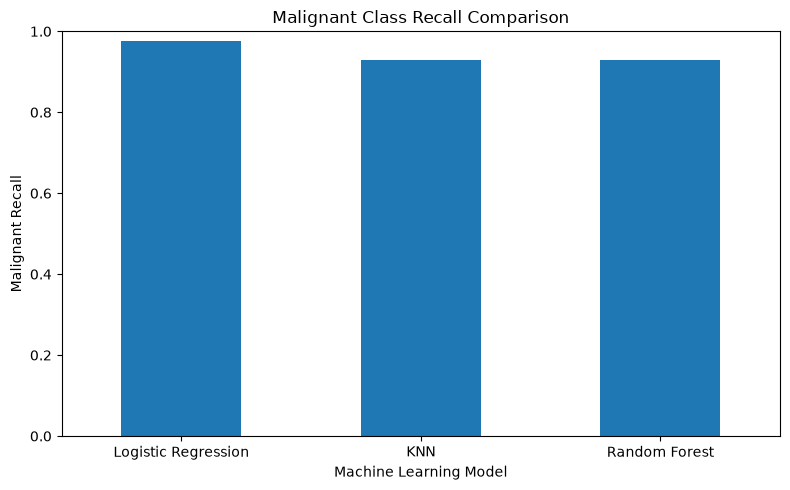

In [62]:
results_df["Malignant Recall"].plot(
    kind="bar",
    figsize=(8, 5)
)


plt.title("Malignant Class Recall Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Malignant Recall")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


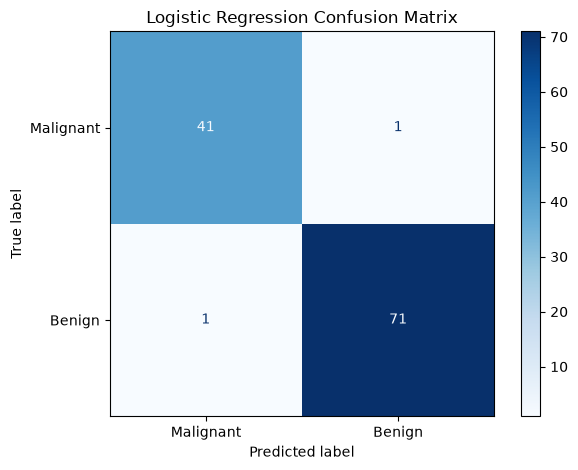

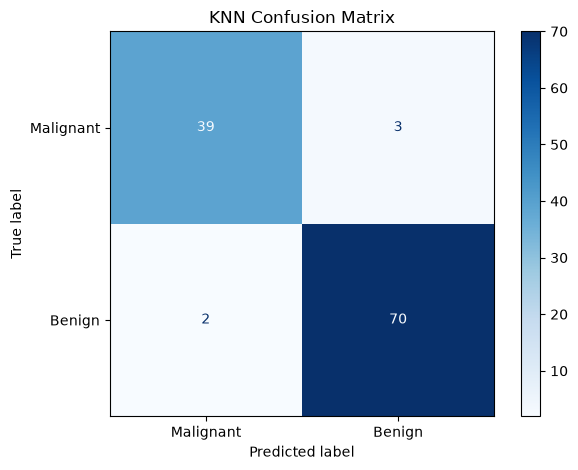

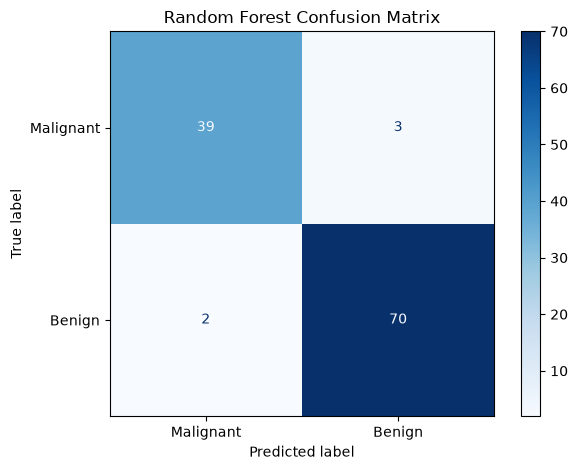

In [63]:
from sklearn.metrics import ConfusionMatrixDisplay


for name, predictions in all_predictions.items():


    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )


    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )


    display.plot(cmap="Blues")


    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()


Error Analysis

The confusion matrices provide additional information about the classification errors made by each model.
Logistic Regression correctly classified 41 malignant cases and missed one malignant case by predicting it as benign.
K-Nearest Neighbours and Random Forest each correctly classified 39 malignant cases and incorrectly classified three malignant cases as benign.
For the benign class, Logistic Regression incorrectly classified one benign sample as malignant, while K-Nearest Neighbours and Random Forest each incorrectly classified two benign samples as malignant.
These results show that Logistic Regression made fewer classification errors than the other two models on the selected test set.
However, the findings are limited to this particular dataset split and do not establish that Logistic Regression will consistently outperform the other algorithms on independent datasets.



10. Limitations of the Experiment

Although the experiment provides a useful baseline comparison, several limitations should be considered when interpreting the results.

1. Single train-test split: The models were evaluated using one stratified 80/20 train-test split. Their performance may vary with different data partitions.
2. Limited model selection: Only three classical machine learning algorithms were evaluated. Other algorithms and configurations may produce different results.
3. Limited hyperparameter optimisation: The experiment used predefined model configurations rather than an extensive hyperparameter search.
4. Dataset limitations: The experiment used the Breast Cancer Wisconsin Diagnostic dataset. Its results may not represent performance on other datasets or populations.
5. No external validation: The models were not evaluated on an independent external dataset.
6. Clinical limitations: This experiment is educational and does not establish clinical reliability, medical suitability or readiness for deployment.
These limitations mean that the findings should be interpreted as preliminary results from a baseline classification experiment.


Conclusion

This project compared the performance of Logistic Regression, K-Nearest Neighbours and Random Forest on the Breast Cancer Wisconsin Diagnostic dataset.
The models were evaluated using an 80/20 stratified train-test split and assessed through accuracy, precision, recall, F1-score and confusion matrices.
Logistic Regression achieved the highest accuracy of approximately 98.25%, compared with 95.61% for both K-Nearest Neighbours and Random Forest.
It also achieved the highest malignant-class recall among the three models, correctly identifying 41 of the 42 malignant samples in the test set.
K-Nearest Neighbours and Random Forest produced identical confusion matrices in this experiment, although they use different learning approaches.
Based on the results, Logistic Regression demonstrated the strongest baseline performance on the selected test set. However, further experiments using cross-validation, hyperparameter optimisation and independent datasets would be necessary to investigate the consistency and generalisability of these findings.
Overall, the project provided practical experience in data preparation, supervised machine learning, model comparison, performance evaluation and scientific interpretation.
